# 07 — Final Model Evaluation (`Hold-out Test Data`: `9.043` Observasi)

**Skrip CLI:** [`src/07_final_model_evaluation.py`](../src/07_final_model_evaluation.py)  
**Laporan:** [`Laporan_Final_Evaluation_DIFW_KNN.md`](../Laporan_Final_Evaluation_DIFW_KNN.md)

Notebook ini mengimplementasikan simpul konvergensi **`Final Model Evaluation`** pada *flowchart*, tempat:
1. *Hyperparameter* terkunci hasil **Tahap 06 (`Cross-Validation & Hyperparameter Tuning`)** dimuat dari [`selected_hyperparameters.json`](../outputs/cv_tuning/selected_hyperparameters.json).
2. Seluruh model (`E0` s.d. `E5`, ditambah referensi `E1_PR`) dilatih pada **seluruh `36.168` baris `Training / Development Data`**.
3. **`Hold-out Test Data` (`9.043` baris: `7.985` `no` & `1.058` `yes`)** dibuka **satu kali** untuk evaluasi akhir objektif lengkap dengan **95% Paired Bootstrap Confidence Interval** (`n_boot = 1.000`).

## 1. Ringkasan Metrik Evaluasi Final pada Hold-out Test Set (`E0` s.d. `E5`)

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
eval_dir = PROJECT_ROOT / 'outputs' / 'final_evaluation'
cv_dir = PROJECT_ROOT / 'outputs' / 'cv_tuning'

selected = json.loads((cv_dir / 'selected_hyperparameters.json').read_text(encoding='utf-8'))
results_df = pd.read_csv(eval_dir / 'holdout_metrics_all_models.csv')
main_cols = ['model_id', 'model_name', 'config_desc', 'accuracy', 'precision_yes', 'recall_yes', 'f1_yes', 'pr_auc', 'roc_auc', 'mcc', 'g_mean', 'mean_cost', 'cost_reduction_vs_e0_pct', 'fit_sec', 'predict_sec']
display(results_df[main_cols].round(4))

,model_id,model_name,config_desc,accuracy,precision_yes,recall_yes,f1_yes,pr_auc,roc_auc,mcc,g_mean,mean_cost,cost_reduction_vs_e0_pct,fit_sec,predict_sec
0,E0,Standard KNN,"Euclidean k=5, uniform, tau=0.50",0.8884,0.5650,0.2013,0.2969,0.2921,0.7014,0.2907,0.4441,0.4853,0.0000,0.3773,2.5734
1,E1,Optimized KNN (Best CV F1),"Euclidean k=3, uniform, tau=0.50",0.8816,0.4876,0.2420,0.3234,0.2619,0.6779,0.2863,0.4835,0.4732,2.5063,0.3776,0.6173
2,E1_PR,Optimized KNN (Best CV PR-AUC),"Euclidean k=51, distance, tau=0.50",0.8924,0.7094,0.1361,0.2284,0.4042,0.7656,0.2793,0.3676,0.5119,-5.4682,0.3770,0.7267
3,E2,Mixed-Type KNN,"Mixed Uniform k=71, q=0.5, tau=0.50",0.8924,0.7033,0.1389,0.2320,0.4160,0.7733,0.2806,0.3713,0.5106,-5.1948,0.1934,7.8315
4,E3,Feature-Weighted KNN,"DIFW m=0.4, lam=0.15, k=71, q=0.5, tau=0.50",0.8968,0.6731,0.2297,0.3425,0.4479,0.7888,0.3528,0.4757,0.4637,4.4657,1.9781,7.7794
5,E4,Cost-Sensitive KNN,"Mixed Cost k=71, q=0.5, 5:1 (tau=0.1667)",0.8577,0.4125,0.5104,0.4563,0.4160,0.7733,0.3783,0.6791,0.3714,23.4678,0.1934,7.8315
6,E5,DIFW-KNN Lengkap,"DIFW m=0.4, lam=0.15, k=71, q=0.5, 5:1 (tau=0.1667)",0.8628,0.4299,0.5302,0.4748,0.4479,0.7888,0.3998,0.6934,0.3571,26.4297,1.9781,7.7794


## 2. Interval Kepercayaan Bootstrap Berpasangan 95% & Confusion Matrix

In [2]:
ci_df = pd.read_csv(eval_dir / 'holdout_bootstrap_ci_formatted.csv')
cm_df = pd.read_csv(eval_dir / 'holdout_confusion_matrices.csv')
weights_df = pd.read_csv(eval_dir / 'final_full_train_feature_weights.csv')

display(ci_df)
display(cm_df)
print('=== Bobot Fitur Final DIFW-KNN pada Seluruh 36.168 Data Training ===')
display(weights_df.round(5))

=== Bobot Fitur Final DIFW-KNN pada Seluruh 36.168 Data Training ===


,model_id,model_name,accuracy,precision_yes,recall_yes,f1_yes,pr_auc,roc_auc,mcc,g_mean,mean_cost
0,E0,Standard KNN,"0.8884 [0.8823, 0.8946]","0.5650 [0.5153, 0.6121]","0.2013 [0.1775, 0.2247]","0.2969 [0.2658, 0.3257]","0.2921 [0.2651, 0.3184]","0.7014 [0.6858, 0.7186]","0.2907 [0.2584, 0.3204]","0.4441 [0.4170, 0.4692]","0.4853 [0.4577, 0.5143]"
1,E1,Optimized KNN (Best CV F1),"0.8816 [0.8750, 0.8875]","0.4876 [0.4465, 0.5269]","0.2420 [0.2167, 0.2671]","0.3234 [0.2934, 0.3502]","0.2619 [0.2398, 0.2866]","0.6779 [0.6626, 0.6941]","0.2863 [0.2550, 0.3145]","0.4835 [0.4575, 0.5079]","0.4732 [0.4460, 0.5019]"
2,E1_PR,Optimized KNN (Best CV PR-AUC),"0.8924 [0.8862, 0.8983]","0.7094 [0.6473, 0.7747]","0.1361 [0.1151, 0.1565]","0.2284 [0.1970, 0.2591]","0.4042 [0.3729, 0.4383]","0.7656 [0.7478, 0.7827]","0.2793 [0.2460, 0.3135]","0.3676 [0.3380, 0.3941]","0.5119 [0.4825, 0.5431]"
3,E2,Mixed-Type KNN,"0.8924 [0.8861, 0.8985]","0.7033 [0.6417, 0.7647]","0.1389 [0.1183, 0.1604]","0.2320 [0.2010, 0.2633]","0.4160 [0.3860, 0.4490]","0.7733 [0.7560, 0.7895]","0.2806 [0.2473, 0.3131]","0.3713 [0.3427, 0.3990]","0.5106 [0.4806, 0.5410]"
4,E3,Feature-Weighted KNN,"0.8968 [0.8907, 0.9027]","0.6731 [0.6237, 0.7185]","0.2297 [0.2054, 0.2554]","0.3425 [0.3118, 0.3734]","0.4479 [0.4174, 0.4811]","0.7888 [0.7720, 0.8056]","0.3528 [0.3207, 0.3835]","0.4757 [0.4497, 0.5013]","0.4637 [0.4351, 0.4928]"
5,E4,Cost-Sensitive KNN,"0.8577 [0.8508, 0.8644]","0.4125 [0.3864, 0.4390]","0.5104 [0.4794, 0.5406]","0.4563 [0.4299, 0.4809]","0.4160 [0.3860, 0.4490]","0.7733 [0.7560, 0.7895]","0.3783 [0.3507, 0.4061]","0.6791 [0.6594, 0.6991]","0.3714 [0.3495, 0.3950]"
6,E5,DIFW-KNN Lengkap,"0.8628 [0.8558, 0.8694]","0.4299 [0.4006, 0.4564]","0.5302 [0.5000, 0.5596]","0.4748 [0.4483, 0.4981]","0.4479 [0.4174, 0.4811]","0.7888 [0.7720, 0.8056]","0.3998 [0.3711, 0.4250]","0.6934 [0.6733, 0.7123]","0.3571 [0.3347, 0.3805]"


,model_id,model_name,threshold,tn,fp,fn,tp,total_cost,mean_cost,cost_reduction_vs_e0_pct
0,E0,Standard KNN,0.500000,7821,164,845,213,4389.0,0.4853,0.00
1,E1,Optimized KNN (Best CV F1),0.500000,7716,269,802,256,4279.0,0.4732,2.51
2,E1_PR,Optimized KNN (Best CV PR-AUC),0.500000,7926,59,914,144,4629.0,0.5119,-5.47
3,E2,Mixed-Type KNN,0.500000,7923,62,911,147,4617.0,0.5106,-5.19
4,E3,Feature-Weighted KNN,0.500000,7867,118,815,243,4193.0,0.4637,4.47
5,E4,Cost-Sensitive KNN,0.166667,7216,769,518,540,3359.0,0.3714,23.47
6,E5,DIFW-KNN Lengkap,0.166667,7241,744,497,561,3229.0,0.3571,26.43


,feature,weight,uniform_weight,relative_importance,weight_pct
0,month,0.30730,0.0625,4.91684,30.73026
1,poutcome,0.10295,0.0625,1.64727,10.29545
2,day,0.09710,0.0625,1.55360,9.70999
3,age,0.09125,0.0625,1.46002,9.12515
4,previously_contacted,0.08656,0.0625,1.38503,8.65643
5,campaign,0.06682,0.0625,1.06906,6.68163
6,balance,0.06240,0.0625,0.99845,6.24029
7,pdays_recency,0.05691,0.0625,0.91051,5.69066
8,contact,0.05078,0.0625,0.81254,5.07835
9,housing,0.03404,0.0625,0.54456,3.40353


## 3. Visualisasi Kurva ROC & Precision–Recall, Interval Kepercayaan 95%, dan Confusion Matrix Grid

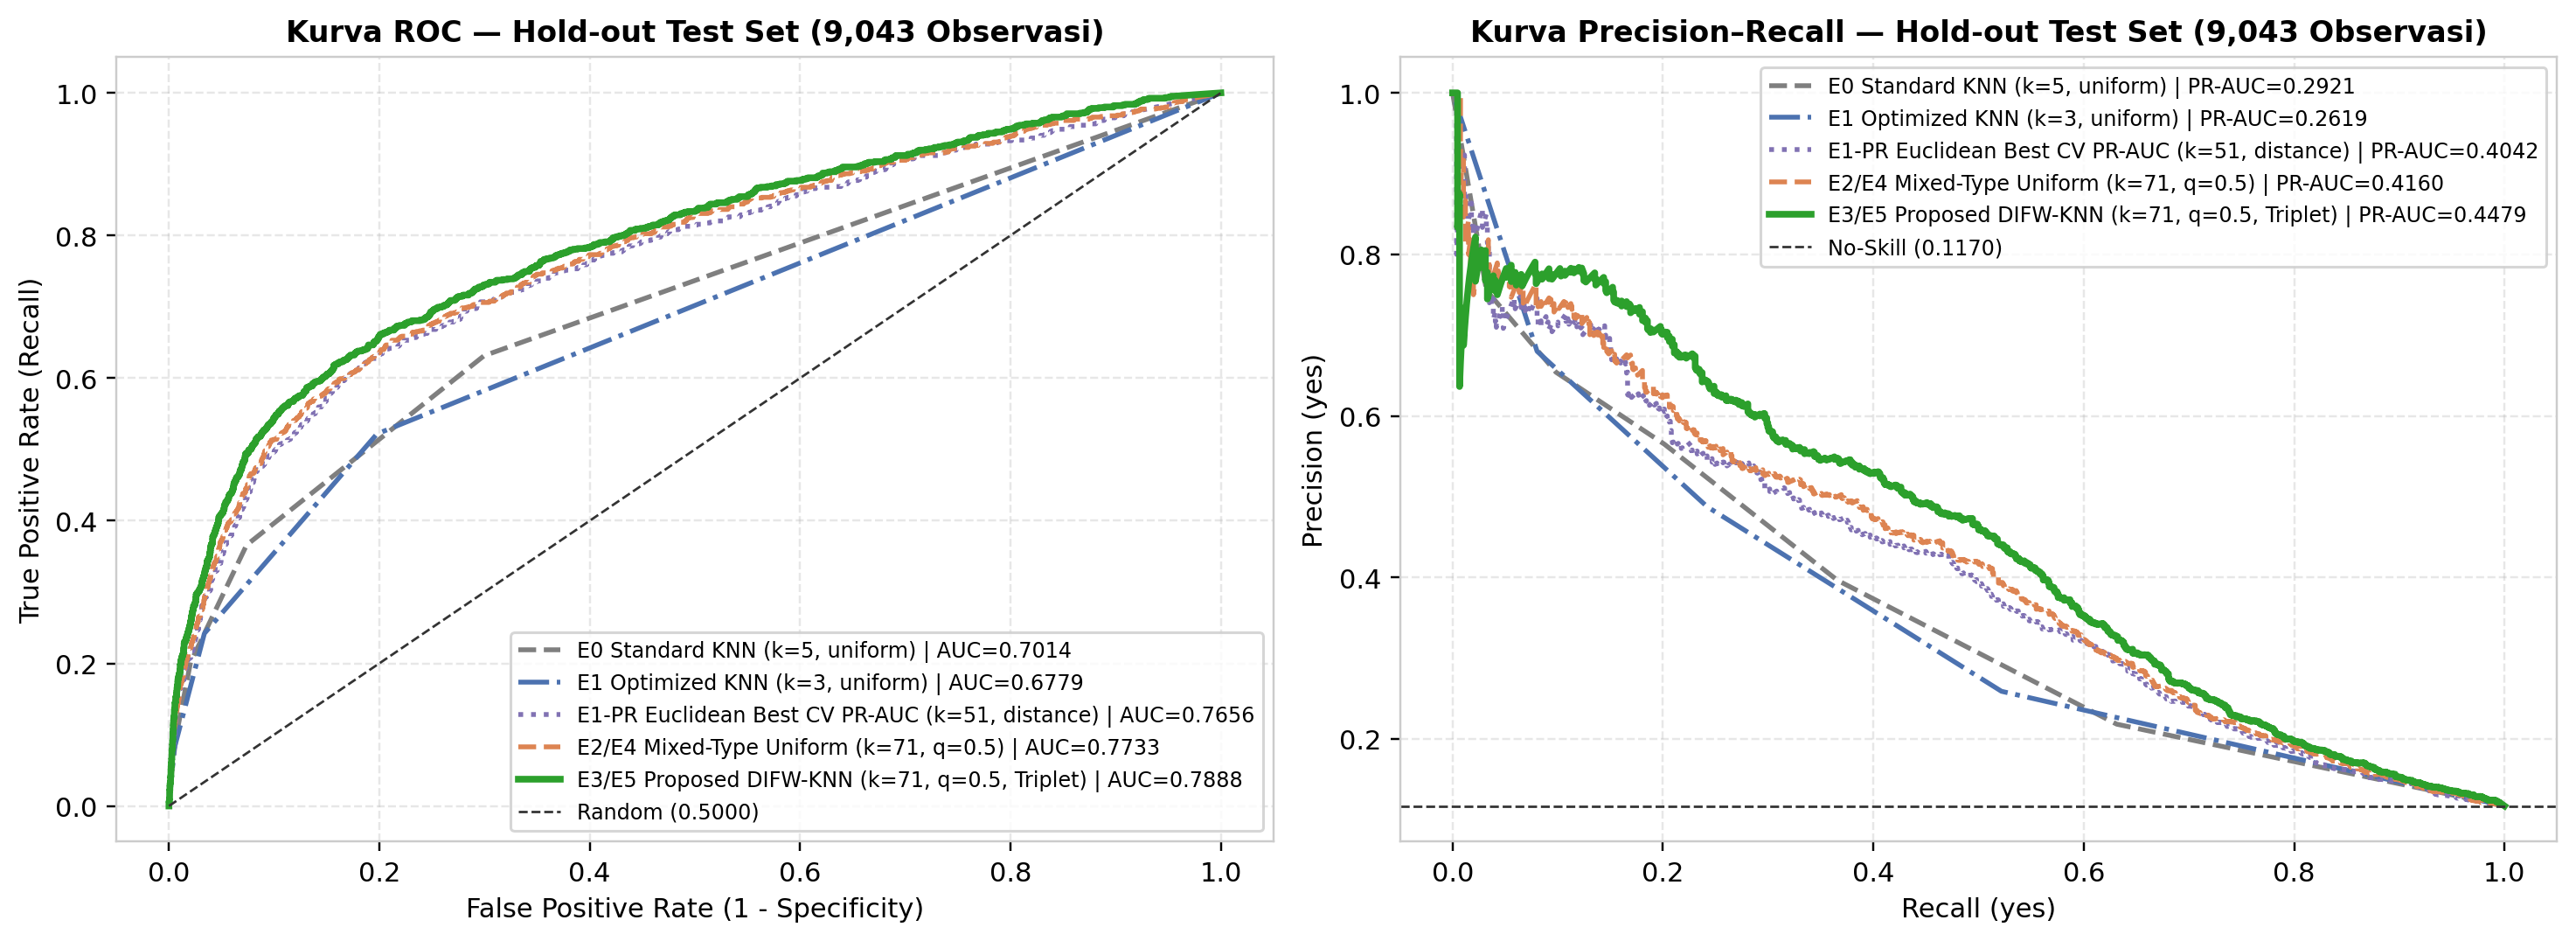

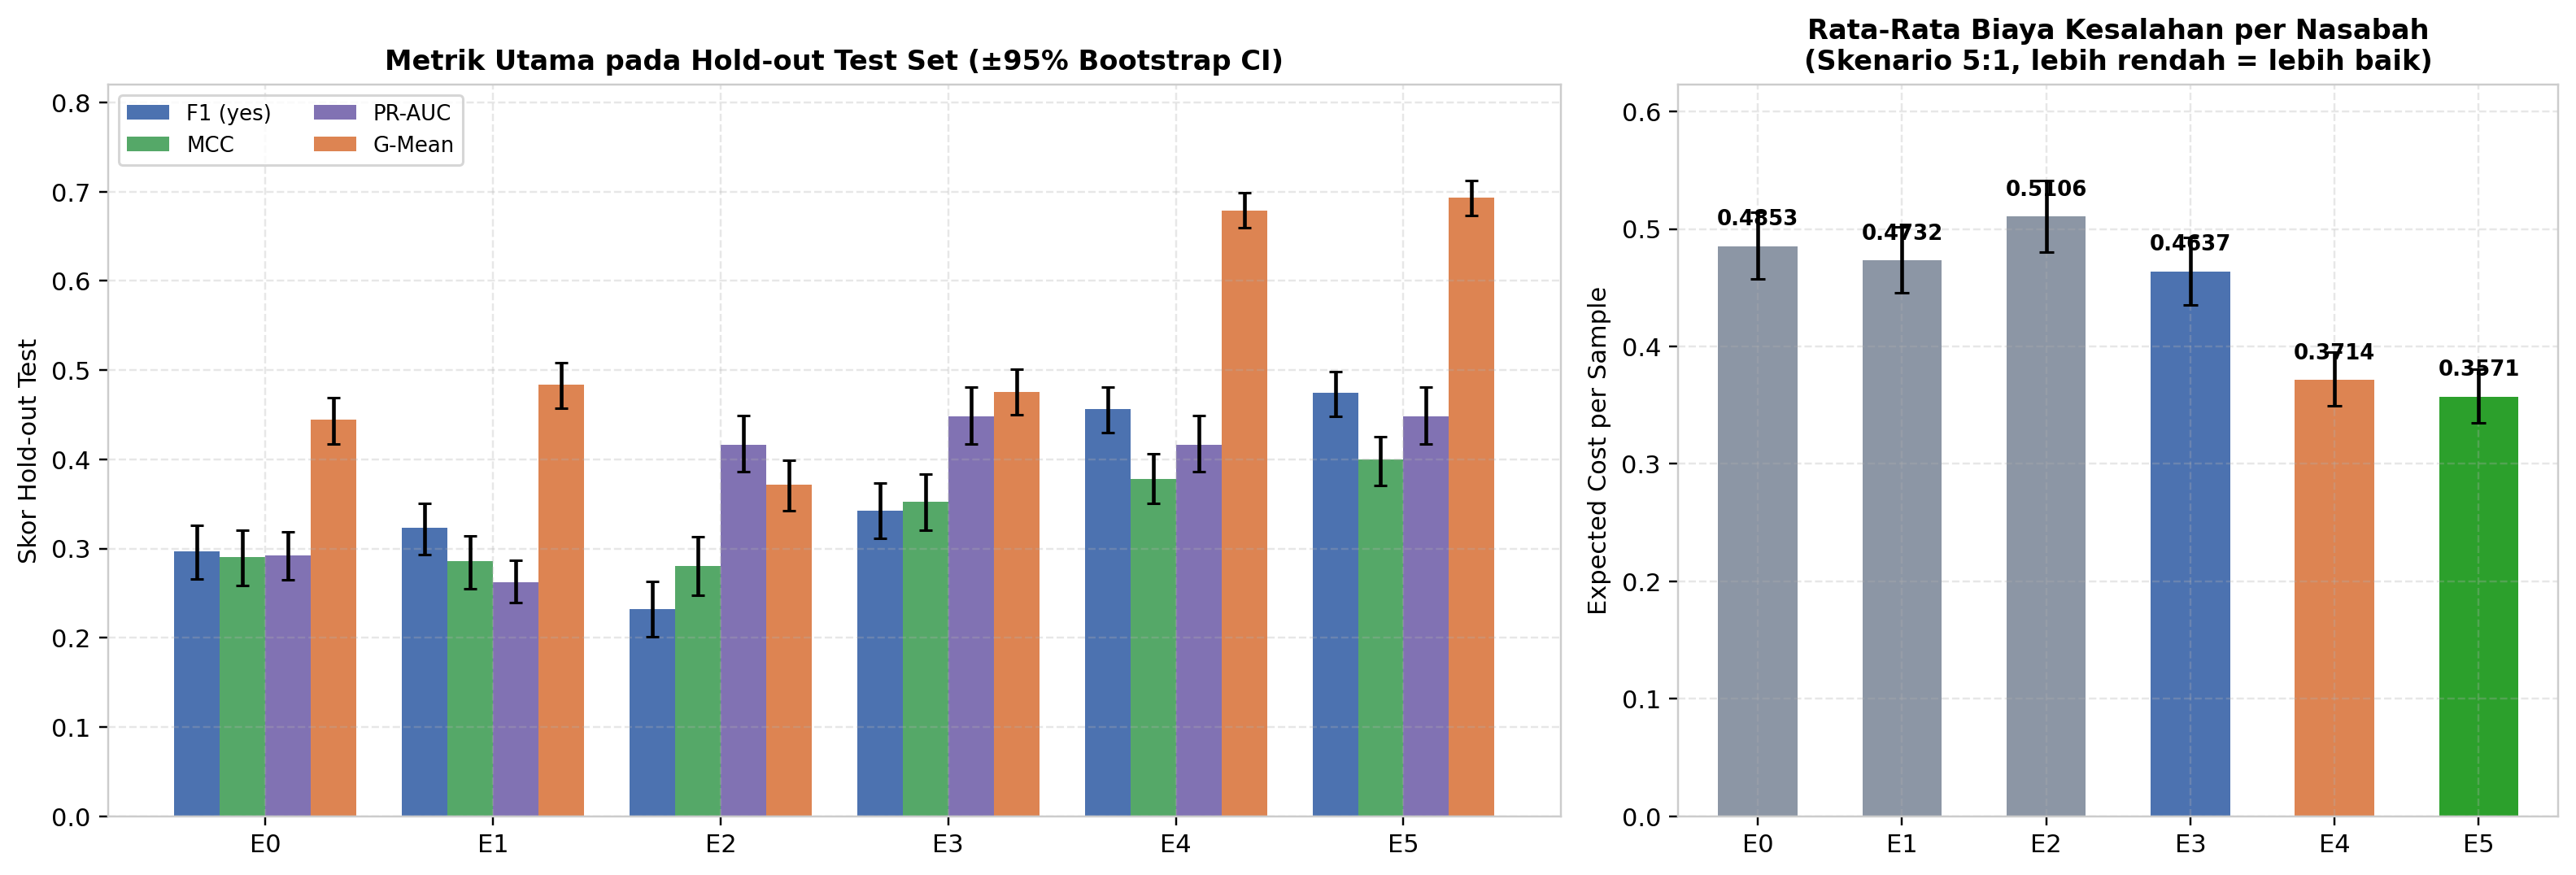

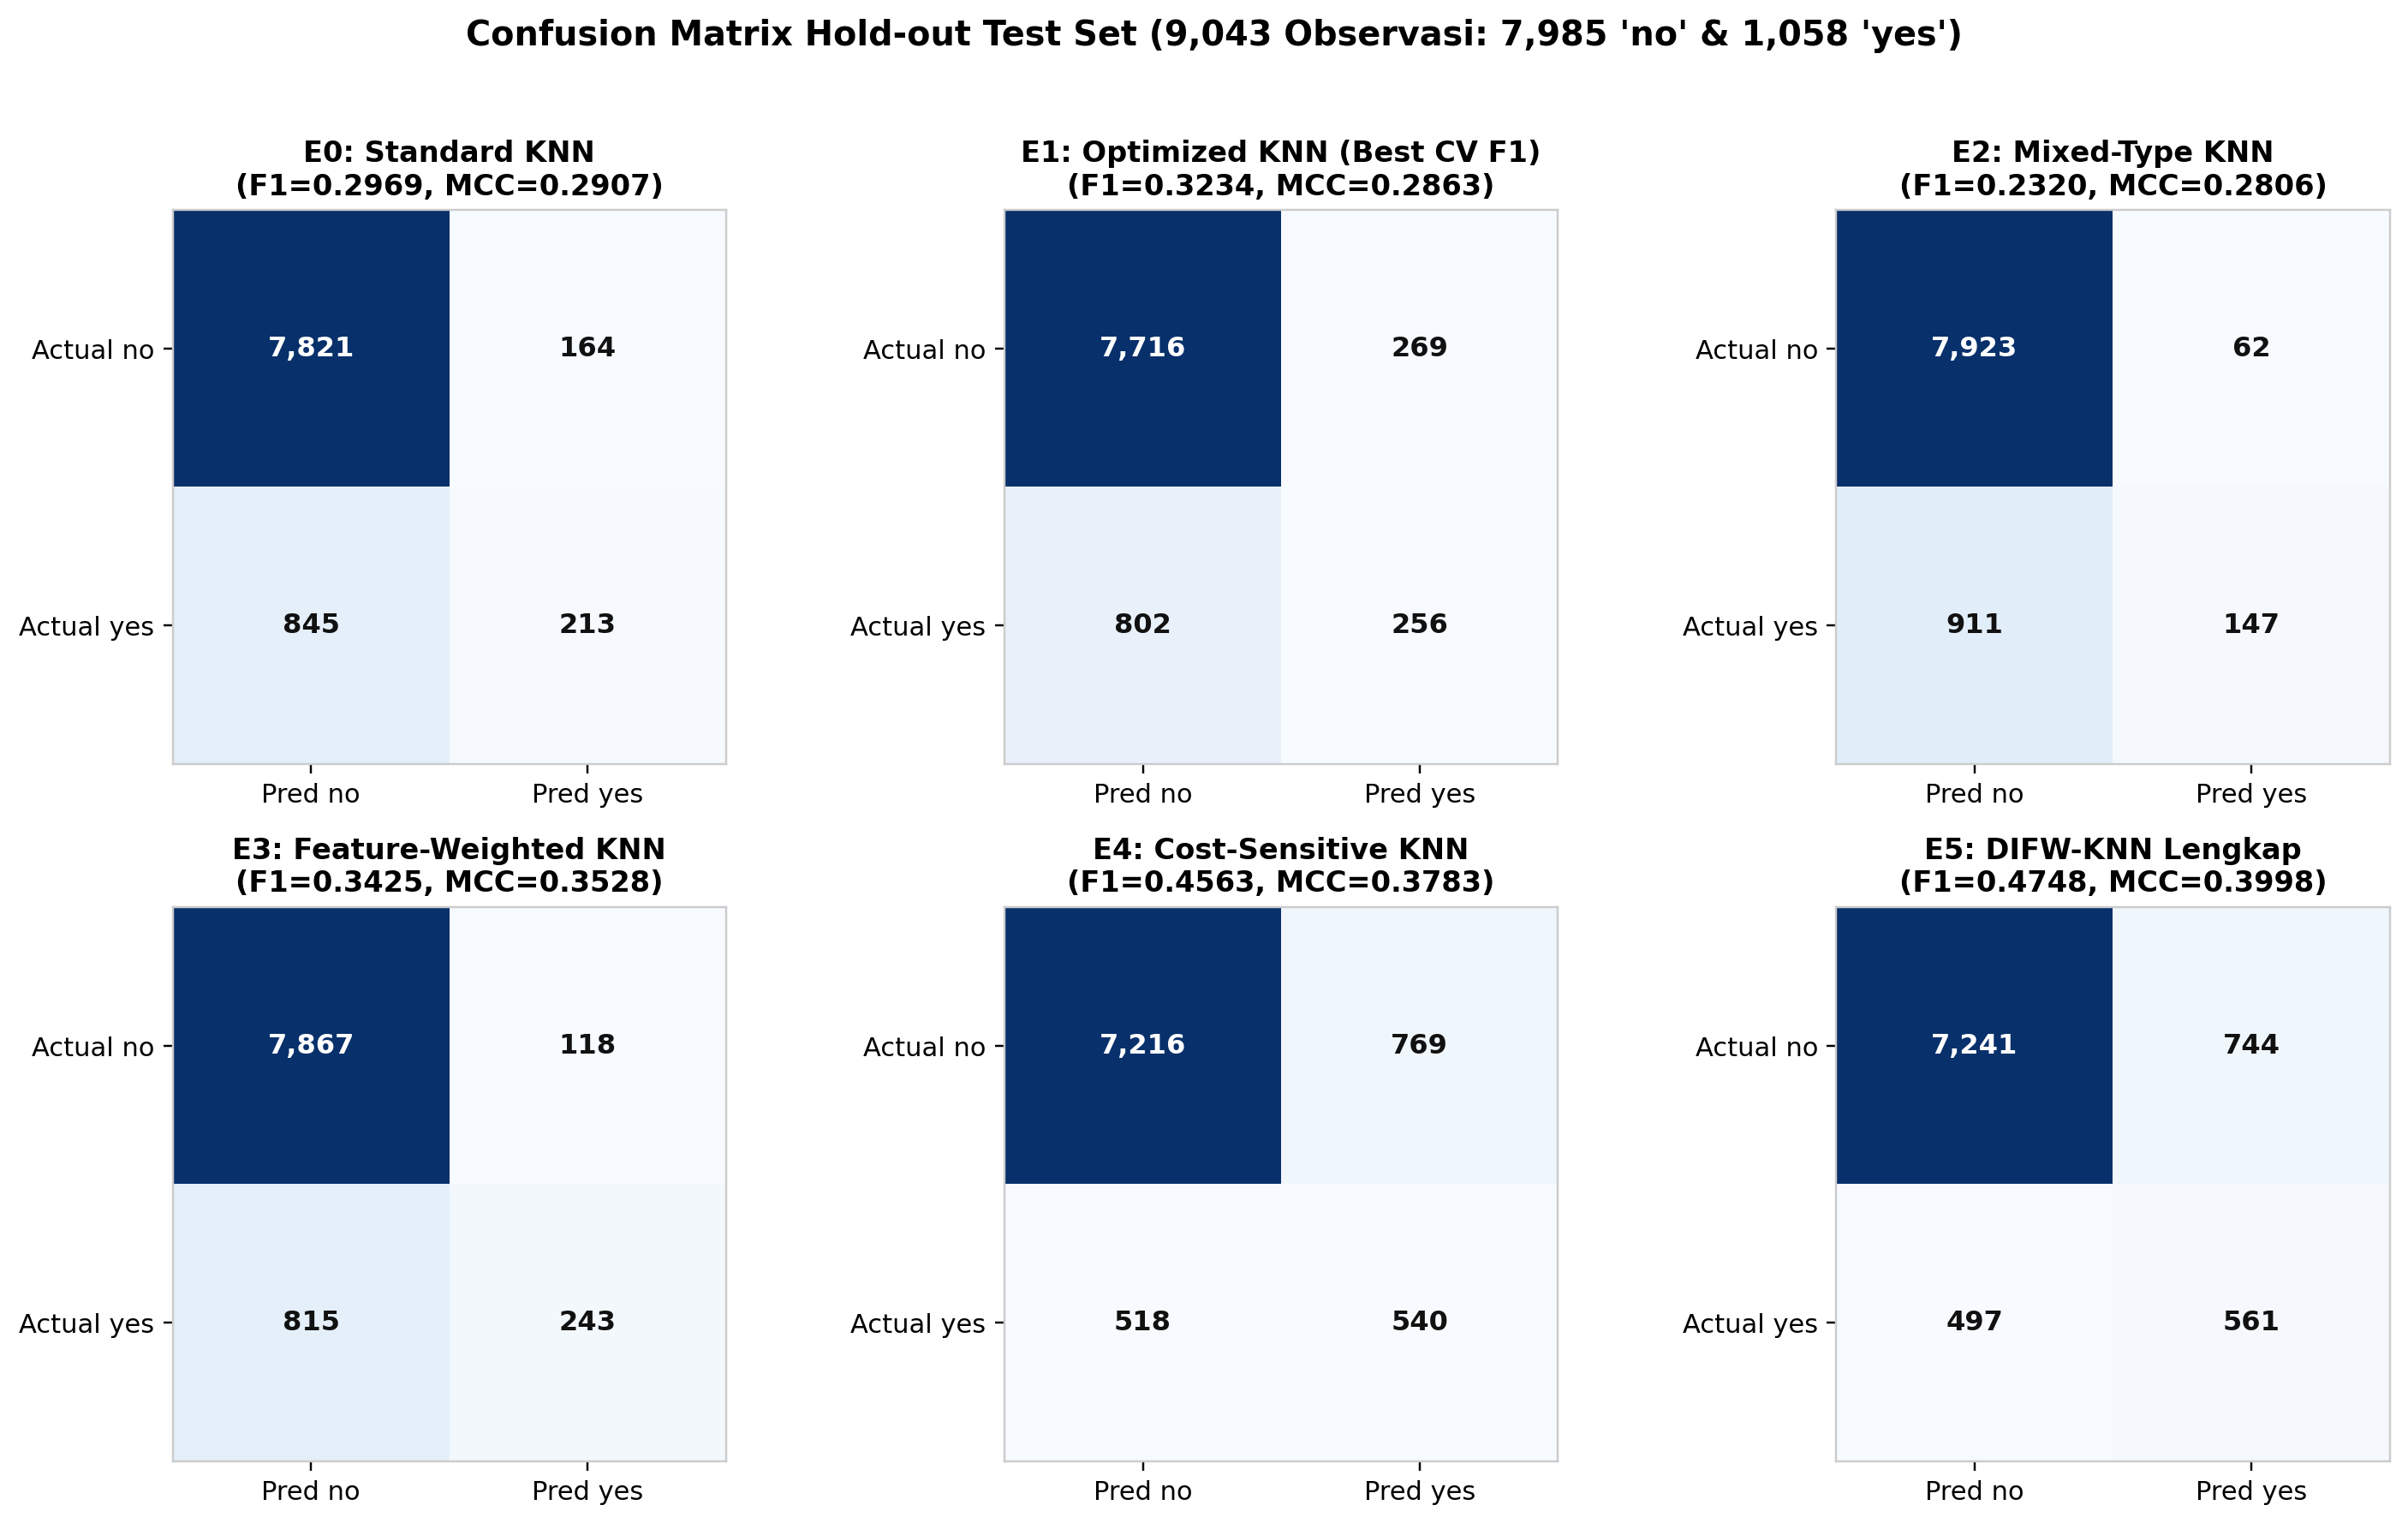

In [3]:
fig_dir = eval_dir / 'figures'
for fname in [
    '01_holdout_roc_and_pr_curves.png',
    '02_holdout_metrics_with_95ci.png',
    '03_holdout_confusion_matrices_grid.png',
]:
    display(Image(fig_dir / fname))